In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import scanpy as sc
import os, warnings 
warnings.filterwarnings('ignore') 

from setup import *
from glob import glob

In [2]:
path = 'plots_website'
if not os.path.exists(path):
    os.mkdir(path)

In [3]:
def plot_stain(adata, sample, path='plots_website/he_stain'):
    fig, ax = plt.subplots(1, 1, figsize=(figsize, figsize), dpi=dpi)
    plt.rc('font', size=fontsize) 
    sc.pl.spatial(adata, ax=ax, show=False, title=sample)

    ax.set_xlabel("")
    ax.set_ylabel("")
    plt.tight_layout(pad=1)
    plt.savefig(f'{path}/{sample}.png')
    # plt.close()
    return

## Ravi et al.

In [6]:
sample_list = []
for x in glob('data/Ravi_processed/gbm_qc/*'):
    sample_list.append(x.split(r'/')[-1][:-5])
sample_list.sort()

adatas = dict() # input of STAN
for sample in sample_list:
    adatas[sample] = sc.read_h5ad(f"data/Ravi_processed/gbm_qc/{sample}.h5ad")

### Visualizing the H&E stained image

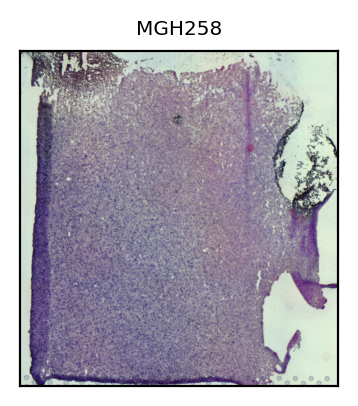

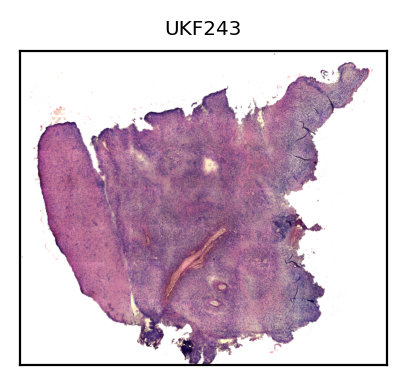

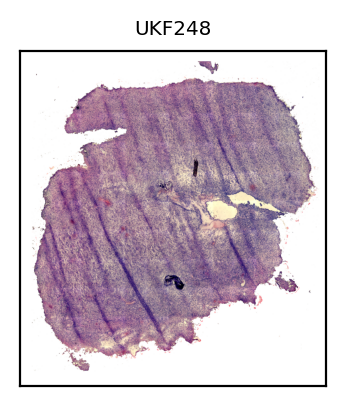

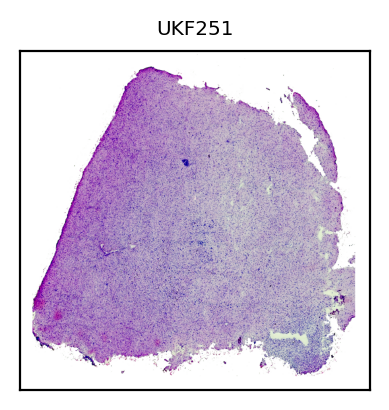

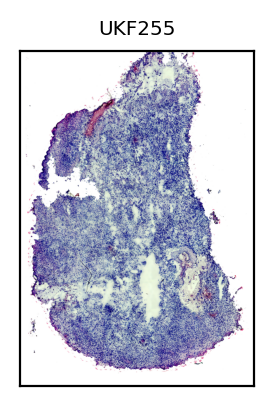

...

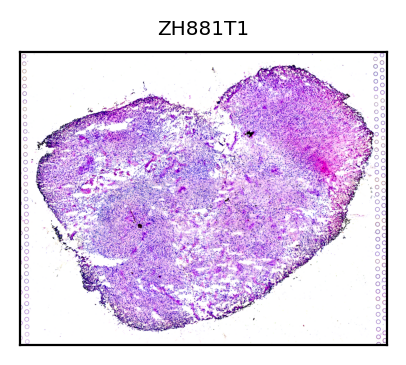

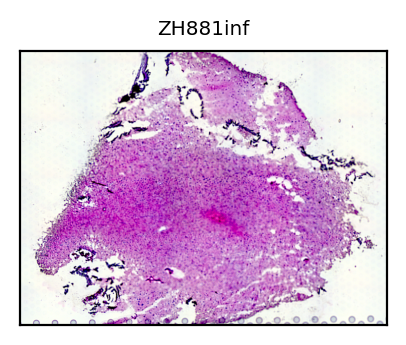

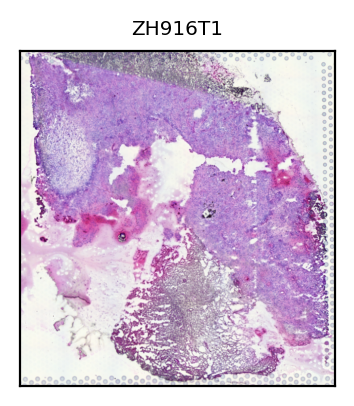

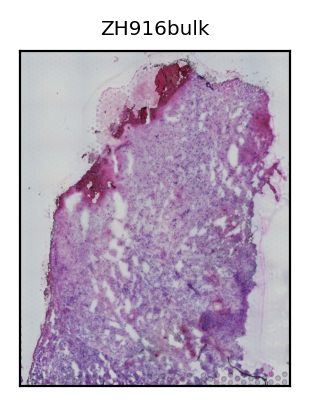

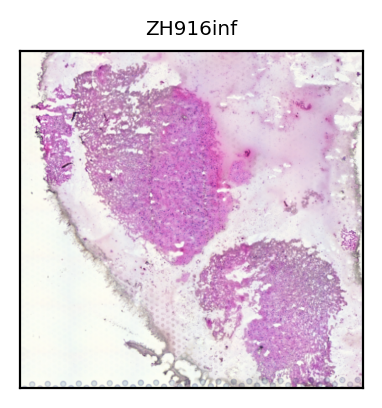

In [7]:
path = 'plots_website/ravi_he_stain'
if not os.path.exists(path):
    os.mkdir(path)
    
for sample in sample_list:
    adata = adatas[sample].copy()
    plot_stain(adata, sample, path)

### Visualizing the metaprograms
https://www.sciencedirect.com/science/article/pii/S0092867424003209

For each group of programs, we defined a consensus program of 50 genes, termed a metaprogram (MP), that reflects a recurrent pattern of heterogeneity in GBM.

In [8]:
# Spatial plots demonstrating spatial organization

def plot_metaprogram(adata, sample, path='plots_website/metaprogram'):
    fig, ax = plt.subplots(1, 1, figsize=(figsize*1.6, figsize), dpi=dpi)
    plt.rc('font', size=fontsize) 
    sc.pl.spatial(adata, color='annotation', palette=metaprogram_palette, alpha_img=0, size=1.8, 
              ax=ax, show=False, title='Metaprogram', legend_fontsize=fontsize*0.8, na_in_legend=False)
    ax.set_xlabel("")
    ax.set_ylabel("")
    plt.tight_layout(pad=1)
    plt.savefig(f'{path}/{sample}.png')
    plt.close()
    return

path = 'plots_website/ravi_metaprogram'
if not os.path.exists(path):
    os.mkdir(path)

for sample in sample_list:
    adata = adatas[sample].copy()
    plot_metaprogram(adata, sample, path)

In [10]:
# Spatial plots demonstrating localization of each MP

def plot_subtype(adata, sample, subtype, path='plots_website/metaprogram'):
    adata.obs['metaprogram'] = [metaprograms[x] for x in adata.obs['annotation']]
    adata.obs['metaprogram'][adata.obs['annotation']==subtype] = subtype
    if len(adata.obs['metaprogram'].unique())==2:
        title = subtype
        fig, ax = plt.subplots(1, 1, figsize=(figsize, figsize), dpi=dpi)
        plt.rc('font', size=fontsize) 
        sc.pl.spatial(adata, color='metaprogram', alpha_img=0, size=1.8, 
                      palette={subtype:metaprogram_palette[subtype], "Other":'#EEEEEE'},
                      ax=ax, show=False, title=title, legend_fontsize=fontsize*0.8, na_in_legend=False)
        ax.set_xlabel("")
        ax.set_ylabel("")
        ax.get_legend().remove()
        plt.tight_layout(pad=1)
        plt.savefig(f'{path}/{sample}.png')
        plt.close()
    return

path = 'plots_website/ravi_metaprogram_single'
if not os.path.exists(path):
    os.mkdir(path)
    
for subtype in metaprograms.keys():
    child_path = f'{path}/{subtype}'
    if not os.path.exists(child_path):
        os.mkdir(child_path)

    for sample in sample_list:
        adata = adatas[sample].copy()
        plot_subtype(adata, sample, subtype, path=child_path)

In [11]:
# Pie charts showing the proportions of spots assigned to each MP

def plot_pie(adata, sample, path='plots_website/metaprogram'):
    data = adata.obs['annotation'].value_counts()/len(adata.obs['annotation'])*100
    x = data[data>1] # only display MPs with percentage >1%
    labels = x.index
    cols = [metaprogram_palette[mp] for mp in labels]
    fig, ax = plt.subplots(1, 1, figsize=(figsize*1.25, figsize*1.25), dpi=dpi)
    plt.rc('font', size=fontsize*0.75) 
    plt.pie(
            x=x, 
            labels=labels,
            autopct='%1.1f%%',
            colors=cols,
            startangle=0, 
        )
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.set_title(sample, fontsize=fontsize)
    plt.tight_layout(pad=1)
    plt.savefig(f'{path}/{sample}.png')
    plt.close()
    return

path = 'plots_website/ravi_metaprogram_pie'
if not os.path.exists(path):
    os.mkdir(path)

for sample in sample_list:
    adata = adatas[sample].copy()
    plot_pie(adata, sample, path=path)

### Metaprogram proportion

In [12]:
df_mp = pd.DataFrame(0, columns = sample_list,
                     index = adatas['UKF255'].obs['annotation'].cat.categories)
for sample in sample_list:
    df_mp[sample] = pd.value_counts(adatas[sample].obs['annotation'])/adatas[sample].n_obs
    
path = 'dataframes/'
if not os.path.exists(path):
    os.mkdir(path)
df_mp.fillna(0).dropna(how='any').to_csv('dataframes/metaprogram_proportion.csv')

## Ren et al.

In [15]:
sample_list = []
for x in glob('data/Ren_processed/*'):
    sample_list.append(x.split(r'/')[-1][:-5])
sample_list.sort()

adatas = dict() # input of STAN
for sample in sample_list:
    adatas[sample] = sc.read_h5ad(f"data/Ren_processed/{sample}.h5ad")

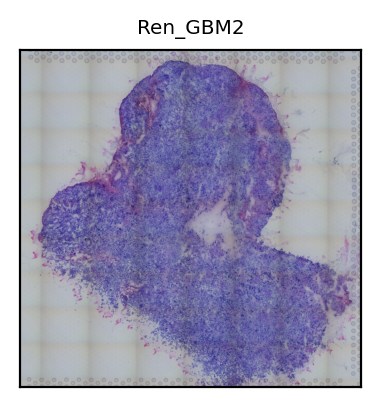

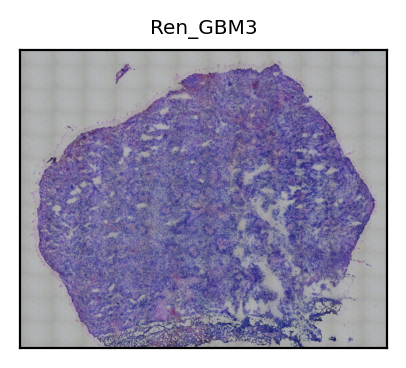

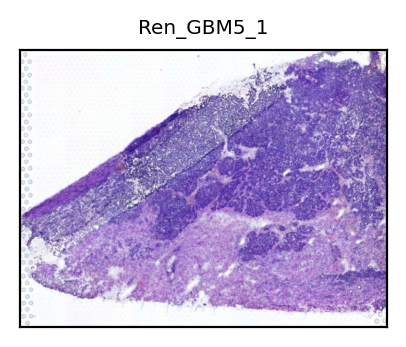

In [16]:
path = 'plots_website/ren_he_stain'
if not os.path.exists(path):
    os.mkdir(path)
    
for sample in sample_list:
    adata = adatas[sample].copy()
    plot_stain(adata, sample, path)

## Sonpatki et al.

In [17]:
sample_list = []
for x in glob('data/Sonpatki_processed/*'):
    sample_list.append(x.split(r'/')[-1][:-5])
sample_list.sort()

adatas = dict() # input of STAN
for sample in sample_list:
    adatas[sample] = sc.read_h5ad(f"data/Sonpatki_processed/{sample}.h5ad")

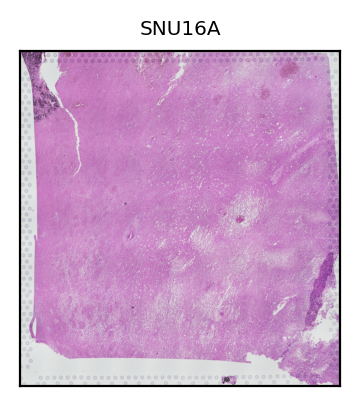

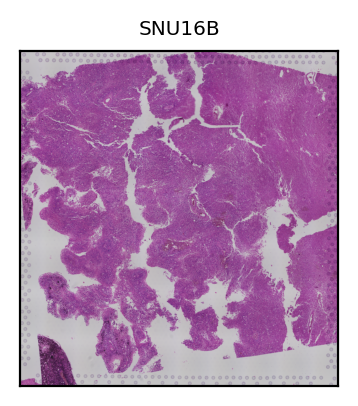

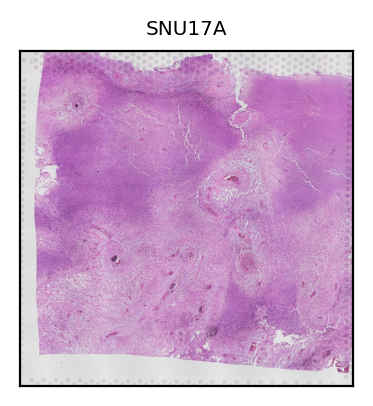

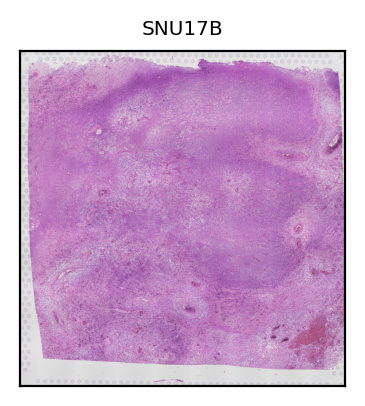

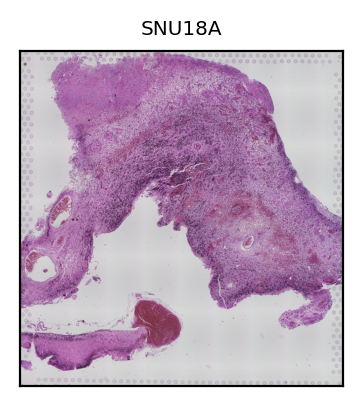

...

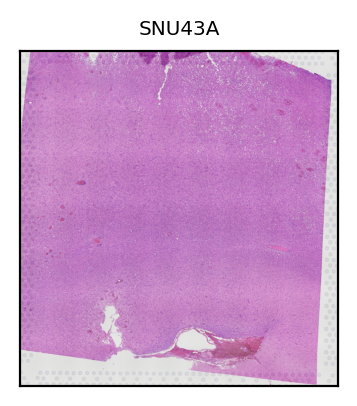

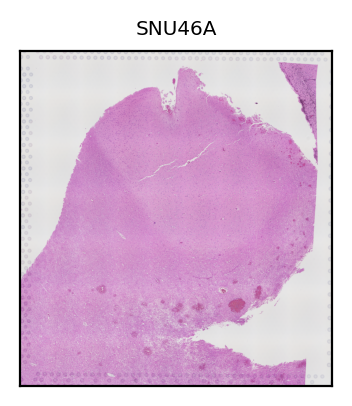

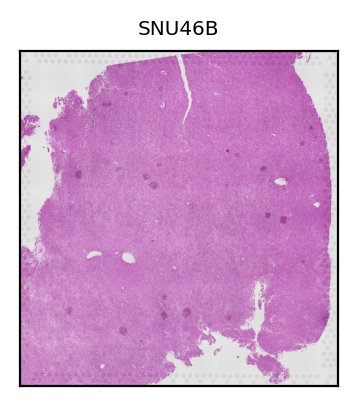

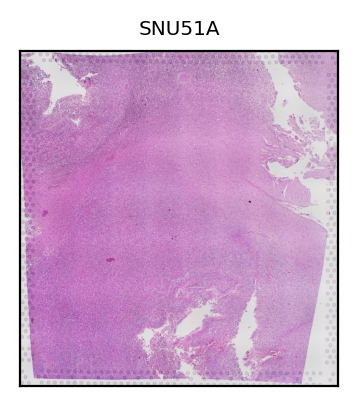

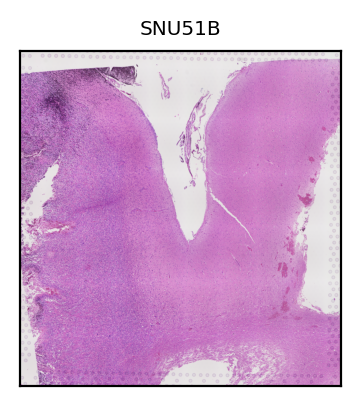

In [18]:
path = 'plots_website/sonpatki_he_stain'
if not os.path.exists(path):
    os.mkdir(path)
    
for sample in sample_list:
    adata = adatas[sample].copy()
    plot_stain(adata, sample, path)